# Лабораторная работа № 01 — прикладная статистика
## Lab01 — sprint 1. Геометрия шрифтов

**Цель:** сравнить размеры букв в разных шрифтах и проверить, насколько они связаны.

<a id="data"></a>
## 1. Данные

В `data/glyph_metrics.csv` — 31 шрифт и 52 латинские буквы для каждого: **1612 наблюдений**.

Случайный эксперимент — выбрать одну пару «шрифт — буква» из таблицы с равной вероятностью. Размер выбранной буквы заранее неизвестен. Если шрифт и буква уже заданы, их размеры фиксированы.

Измеряю три величины: **$X$** — ширина (em), **$Y$** — площадь видимой части (em²), **$Z$** — высота (em). `em` — единица размера относительно кегля шрифта.

![Примеры начертаний](figures/font_specimens.png)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

root = Path('.')
if not (root / 'data/glyph_metrics.csv').exists():
    root = Path('font_lab01')

font_df = pd.read_csv(root / 'data/glyph_metrics.csv')
noto_df = pd.read_csv(root / 'data/noto_multiscript.csv')
rng = np.random.default_rng(42)

colors = {'X':'#2a7894', 'Y':'#b1784b', 'Z':'#6c7c50'}
plt.rcParams.update({'figure.figsize':(9,3.3), 'figure.dpi':115,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.grid':True, 'grid.alpha':0.2,
                     'font.family':'DejaVu Sans'})

assert len(font_df)==1612 and font_df.family.nunique()==31
assert not font_df.isna().any().any()
assert not font_df.duplicated(['family','character']).any()
print('Данные:',font_df.shape,'| Noto:',noto_df.shape)
display(font_df.head())

Данные: (1612, 7) | Noto: (205, 5)


,family,category,character,is_uppercase,advance_em,ink_area_em2,bbox_height_em
0,Inter,sans-serif,a,0,0.561523,0.131759,0.570312
1,Inter,sans-serif,b,0,0.612305,0.150667,0.734375
2,Inter,sans-serif,c,0,0.571289,0.099162,0.562500
3,Inter,sans-serif,d,0,0.612305,0.150555,0.734375
4,Inter,sans-serif,e,0,0.583008,0.132371,0.562500


## 2. Случайные величины

В нашем эксперименте распределения **дискретные**, потому что возможных пар всего 1612. Вероятность значения равна его доле в таблице:

$$P(X=x)=\frac{n_x}{N},\qquad F_X(x)=P(X\le x).$$

$$E(X)=\sum_x xP(X=x),\qquad D(X)=\sum_x(x-E(X))^2P(X=x).$$

Аналогично для $Y$ и $Z$. Ниже — статистики и гистограммы этих распределений.

In [2]:
variables = {
    'X': ('advance_em', 'Ширина, em'),
    'Y': ('ink_area_em2', 'Площадь, em²'),
    'Z': ('bbox_height_em', 'Высота, em')
}

def show_distribution(name):
    col, unit = variables[name]
    a = font_df[col].to_numpy()
    table = pd.DataFrame({
        'N':[len(a)], 'Среднее':[a.mean()], 'Медиана':[np.median(a)],
        'Станд. откл.':[a.std(ddof=0)], 'Дисперсия':[a.var(ddof=0)],
        'Q1':[np.quantile(a,.25)], 'Q3':[np.quantile(a,.75)],
        'Мин.':[a.min()], 'Макс.':[a.max()]
    })
    display(table.round(4))
    fig, axes = plt.subplots(1,2,figsize=(10,3.4))
    axes[0].hist(a,bins=26,color=colors[name],alpha=.85)
    axes[0].set(xlabel=unit,ylabel='Частота, шт.',title=f'{name}: гистограмма')
    values=np.sort(a)
    axes[1].step(values,np.arange(1,len(values)+1)/len(values),where='post',color=colors[name])
    axes[1].set(xlabel=unit,ylabel='Накопленная вероятность',title=f'{name}: функция распределения',ylim=(0,1.02))
    plt.tight_layout()
    plt.show()

<a id="x"></a>
### Random Variable 01 — ширина $X$

Ширина — горизонтальный шаг буквы:

$$X(f,c)=\frac{\operatorname{advanceWidth}(f,c)}{\operatorname{unitsPerEm}(f)}.$$

,N,Среднее,Медиана,Станд. откл.,Дисперсия,Q1,Q3,Мин.,Макс.
0,1612,0.5723,0.6,0.1462,0.0214,0.5,0.6401,0.1821,1.056


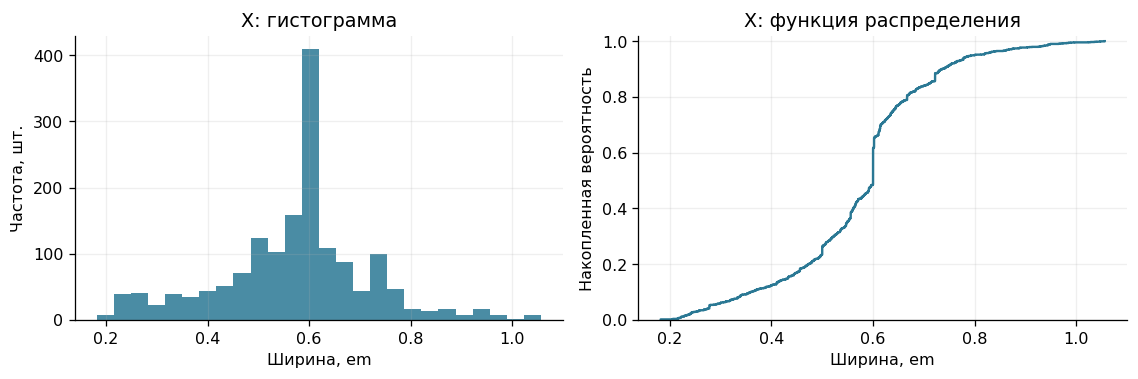

Узкие буквы: j, i, l
Широкие буквы: m, M, W


In [3]:
show_distribution('X')
letter_width=font_df.groupby('character').advance_em.mean().sort_values()
print('Узкие буквы:', ', '.join(letter_width.head(3).index))
print('Широкие буквы:', ', '.join(letter_width.tail(3).index))

<a id="y"></a>
### Random Variable 02 — площадь $Y$

Площадь закрашенной части буквы измерена по яркости пикселей:

$$Y(f,c)=\frac{\sum I_{ij}(f,c)}{255\cdot128^2}.$$

,N,Среднее,Медиана,Станд. откл.,Дисперсия,Q1,Q3,Мин.,Макс.
0,1612,0.1248,0.1209,0.0408,0.0017,0.0942,0.1517,0.0368,0.3193


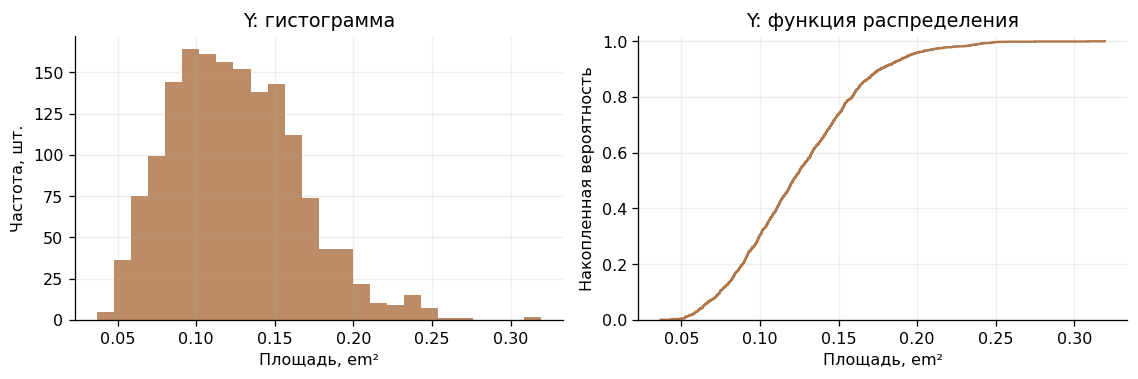

In [4]:
show_distribution('Y')

<a id="z"></a>
### Random Variable 03 — высота $Z$

Высота видимой части буквы:

$$Z(f,c)=\frac{y_{\max}(f,c)-y_{\min}(f,c)}{128}.$$

,N,Среднее,Медиана,Станд. откл.,Дисперсия,Q1,Q3,Мин.,Макс.
0,1612,0.6768,0.7109,0.1021,0.0104,0.5625,0.7266,0.4219,1.0078


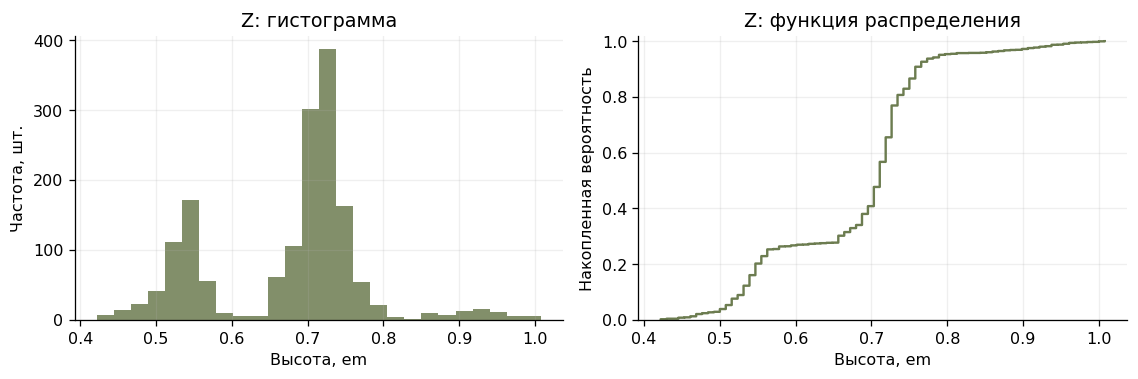

In [5]:
show_distribution('Z')

<a id="dependence"></a>
## 3. Зависимость величин

Сравниваю пары $X$–$Y$, $Y$–$Z$ и $X$–$Z$. Для событий $A=\{X>\operatorname{med}(X)\}$, $B=\{Y>\operatorname{med}(Y)\}$ независимость требует:

$$P(A\cap B)=P(A)P(B).$$

Если равенство не выполняется, величины зависимы. Дополнительно использую коэффициент Спирмена $\rho$.

,Пара,P(A∩B)-P(A)P(B),Спирмен ρ
0,X–Y,0.1321,0.7302
1,Y–Z,0.0732,0.3681
2,X–Z,0.0403,0.1041


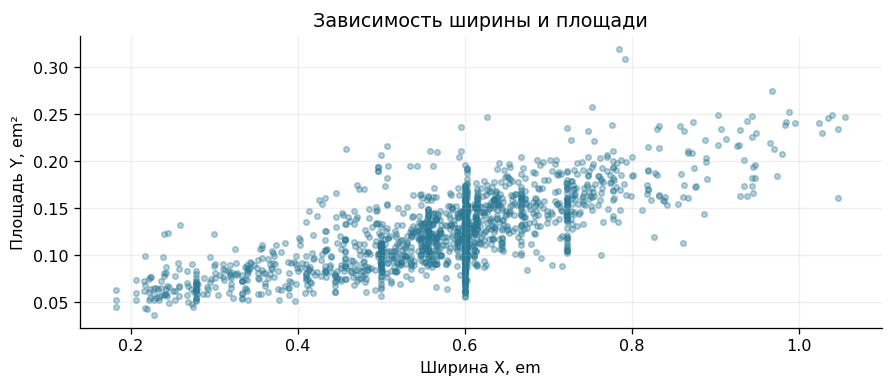

In [6]:
checks=[]
for a,b in [('X','Y'),('Y','Z'),('X','Z')]:
    u=font_df[variables[a][0]]
    v=font_df[variables[b][0]]
    A=u>u.median()
    B=v>v.median()
    delta=(A&B).mean()-A.mean()*B.mean()
    rho=stats.spearmanr(u,v).statistic
    checks.append({'Пара':f'{a}–{b}', 'P(A∩B)-P(A)P(B)':delta, 'Спирмен ρ':rho})
display(pd.DataFrame(checks).round(4))

fig,ax=plt.subplots()
ax.scatter(font_df.advance_em,font_df.ink_area_em2,s=12,alpha=.35,color=colors['X'])
ax.set(xlabel='Ширина X, em',ylabel='Площадь Y, em²',title='Зависимость ширины и площади')
plt.show()

<a id="normalization"></a>
## 4. Нормализация

Стандартизация приводит среднее к нулю, а стандартное отклонение — к единице. Min–max переводит значения в диапазон от 0 до 1:

$$z=\frac{x-\mu}{\sigma},\qquad x_{norm}=\frac{x-x_{min}}{x_{max}-x_{min}}.$$

Это **не означает**, что данные стали нормально распределёнными. Нормальность проверяю отдельно ($H_0$: распределение нормальное).

In [7]:
cols=[v[0] for v in variables.values()]
a=font_df[cols]
z=(a-a.mean())/a.std(ddof=0)
minmax=(a-a.min())/(a.max()-a.min())
normal_rows=[]
for label,(col,unit) in variables.items():
    p=stats.normaltest(font_df[col]).pvalue
    normal_rows.append({'Величина':label,'Среднее z':z[col].mean(),
                        'σ z':z[col].std(ddof=0),'Мин. min–max':minmax[col].min(),
                        'Макс. min–max':minmax[col].max(),
                        'p нормальности':p,'Нормальность при α=0,05':'нет' if p<.05 else 'не отвергнута'})
display(pd.DataFrame(normal_rows).round(5))

,Величина,Среднее z,σ z,Мин. min–max,Макс. min–max,p нормальности,"Нормальность при α=0,05"
0,X,0.0,1.0,0.0,1.0,0.00000,нет
1,Y,0.0,1.0,0.0,1.0,0.00000,нет
2,Z,-0.0,1.0,0.0,1.0,0.01176,нет


<a id="samples"></a>
## 5. Выборки и состоятельность

Генеральная совокупность — **все 1612 измерений**. Беру две выборки по 240 наблюдений: с возвращением (пара может повторяться) и без возвращения (не повторяется).

$$\bar X=\frac1n\sum_{i=1}^{n}X_i,\qquad s^2=\frac1{n-1}\sum_{i=1}^{n}(X_i-\bar X)^2.$$

Чтобы проверить состоятельность среднего и дисперсии, повторяю выборку при разных $n$ и измеряю **MSE** — среднюю квадратичную ошибку. Для среднего при отборе без возвращения:

$$\operatorname{Var}(\bar X)=\frac{\sigma^2}{n}\frac{N-n}{N-1};\qquad\text{с возвращением: }\operatorname{Var}(\bar X)=\frac{\sigma^2}{n}.$$

In [8]:
n=240
with_replacement=font_df.iloc[rng.choice(len(font_df),n,replace=True)]
without_replacement=font_df.iloc[rng.choice(len(font_df),n,replace=False)]
rows=[]
for label,(col,unit) in variables.items():
    for method,frame in [('Вся таблица',font_df),('С возвращением',with_replacement),
                         ('Без возвращения',without_replacement)]:
        rows.append({'Величина':label,'Данные':method,'N':len(frame),
                     'Среднее':frame[col].mean(),
                     'Дисперсия':frame[col].var(ddof=0 if method=='Вся таблица' else 1),
                     'Медиана':frame[col].median()})
display(pd.DataFrame(rows).round(5))

,Величина,Данные,N,Среднее,Дисперсия,Медиана
0,X,Вся таблица,1612,0.57226,0.02138,0.60000
1,X,С возвращением,240,0.55679,0.01938,0.59390
2,X,Без возвращения,240,0.58036,0.02065,0.60000
3,Y,Вся таблица,1612,0.12483,0.00166,0.12094
4,Y,С возвращением,240,0.12194,0.00144,0.12172
5,Y,Без возвращения,240,0.12732,0.00182,0.12341
6,Z,Вся таблица,1612,0.67683,0.01043,0.71094
7,Z,С возвращением,240,0.68372,0.01122,0.71094
8,Z,Без возвращения,240,0.66514,0.00958,0.70312


,Величина,n,Метод,MSE среднего / D,MSE дисперсии / D²
0,X,25,с возвращением,0.038626,0.138537
4,X,250,с возвращением,0.002709,0.009525
8,X,1000,с возвращением,0.001025,0.002862
12,Y,25,с возвращением,0.043627,0.111156
16,Y,250,с возвращением,0.003718,0.009138
20,Y,1000,с возвращением,0.001011,0.002711
24,Z,25,с возвращением,0.035383,0.085891
28,Z,250,с возвращением,0.003431,0.008775
32,Z,1000,с возвращением,0.000938,0.001858


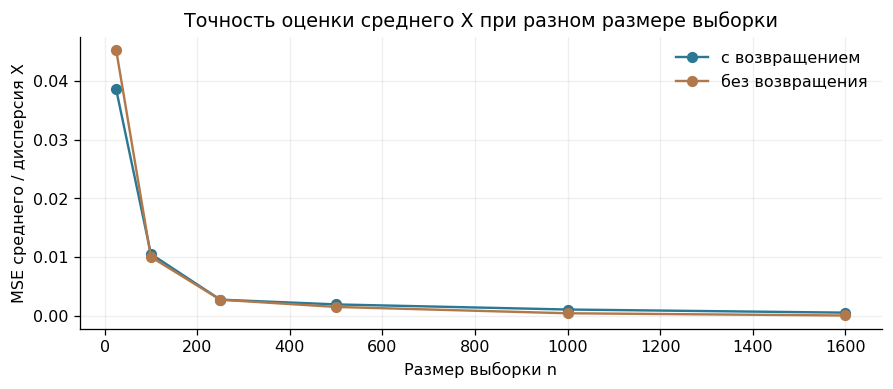

In [9]:
sizes=[25,100,250,500,1000,1600]
results=[]
repeat_rng=np.random.default_rng(100)
for label,(col,unit) in variables.items():
    full=font_df[col].to_numpy()
    mean=full.mean()
    variance=full.var(ddof=0)
    for size in sizes:
        for replace in [True,False]:
            means=[]
            variances=[]
            for _ in range(200):
                sample=repeat_rng.choice(full,size=size,replace=replace)
                means.append(sample.mean())
                variances.append(sample.var(ddof=1))
            results.append({'Величина':label,'n':size,
                            'Метод':'с возвращением' if replace else 'без возвращения',
                            'MSE среднего / D':np.mean((np.array(means)-mean)**2)/variance,
                            'MSE дисперсии / D²':np.mean((np.array(variances)-variance)**2)/variance**2})
errors=pd.DataFrame(results)
display(errors[(errors['Метод']=='с возвращением') & (errors['n'].isin([25,250,1000]))].round(6))

fig,ax=plt.subplots()
for method,color in [('с возвращением',colors['X']),('без возвращения',colors['Y'])]:
    t=errors[(errors['Величина']=='X') & (errors['Метод']==method)]
    ax.plot(t['n'],t['MSE среднего / D'],marker='o',label=method,color=color)
ax.set(xlabel='Размер выборки n',ylabel='MSE среднего / дисперсия X',
       title='Точность оценки среднего X при разном размере выборки')
ax.legend(frameon=False)
plt.show()

<a id="hypothesis"></a>
## 6. Проверка гипотезы

Проверяю, отличается ли средняя ширина букв у моноширинных и sans-serif шрифтов:

$$H_0:\mu_{mono}=\mu_{sans},\qquad H_1:\mu_{mono}\ne\mu_{sans},\quad \alpha=0.05.$$

Для сравнения беру **среднюю ширину 52 букв каждого шрифта**, а не все буквы по отдельности. Использую перестановочный тест.

In [10]:
family_means=font_df.groupby(['family','category'],as_index=False).advance_em.mean()
mono=family_means.loc[family_means.category=='monospace','advance_em'].to_numpy()
sans=family_means.loc[family_means.category=='sans-serif','advance_em'].to_numpy()
res=stats.permutation_test((mono,sans),
                           statistic=lambda x,y: x.mean()-y.mean(),
                           n_resamples=20000,alternative='two-sided',random_state=2026)
display(pd.DataFrame([{'Моноширинные, n':len(mono),'Sans-serif, n':len(sans),
                       'Среднее mono, em':mono.mean(), 'Среднее sans, em':sans.mean(),
                       'Разница, em':mono.mean()-sans.mean(),'p-value':res.pvalue}]).round(5))
print('Решение:', 'H0 отвергается' if res.pvalue<.05 else 'H0 не отвергается')

,"Моноширинные, n","Sans-serif, n","Среднее mono, em","Среднее sans, em","Разница, em",p-value
0,5,16,0.60043,0.5532,0.04723,0.0173


Решение: H0 отвергается


<a id="extra"></a>
## 7. Дополнительный датасет КТвД

В `data/noto_multiscript.csv` — **205 шрифтовых файлов Noto**. Случайно выбираю один файл и измеряю две величины: **$W$** — количество поддерживаемых символов (шт.) и **$S$** — размер файла (KiB). Для известного файла эти числа фиксированы.

Проверяю распределения и связь между $W$ и $S$.

,glyph_count,file_size_kib
count,205.00,205.00
mean,229.56,134.60
std,572.10,434.23
min,24.00,4.38
25%,69.00,18.50
50%,99.00,38.81
75%,164.00,124.06
max,6896.00,5089.13


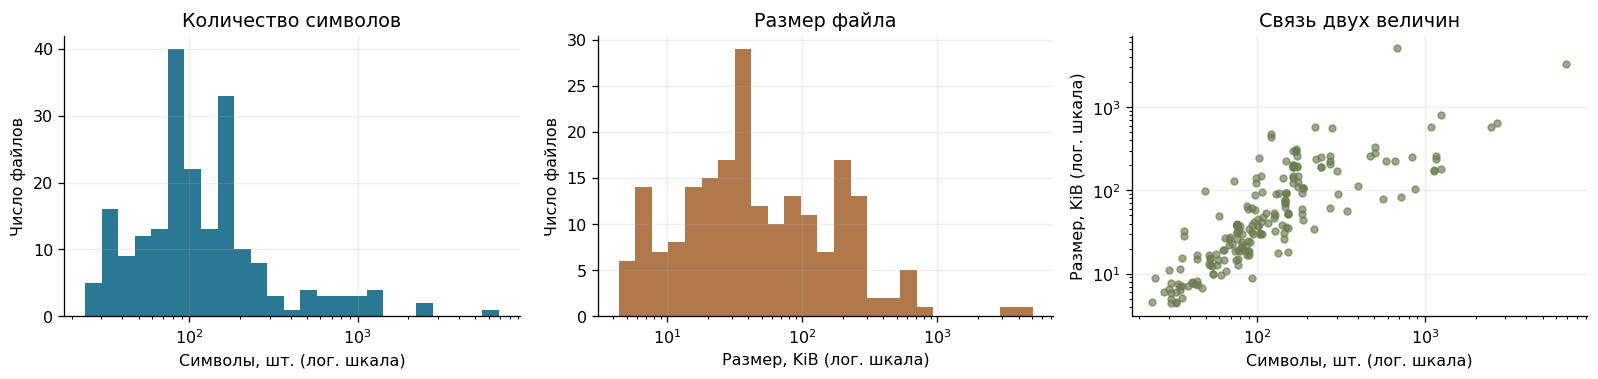

Спирмен: 0.860, p=2.54e-61; разница вероятностей: 0.1817


In [11]:
assert len(noto_df)==205 and not noto_df[['glyph_count','file_size_kib']].isna().any().any()
display(noto_df[['glyph_count','file_size_kib']].describe().round(2))
fig,axes=plt.subplots(1,3,figsize=(14,3.4))
axes[0].hist(noto_df.glyph_count,bins=np.geomspace(noto_df.glyph_count.min(),noto_df.glyph_count.max(),26),color=colors['X'])
axes[0].set(xscale='log',xlabel='Символы, шт. (лог. шкала)',ylabel='Число файлов',title='Количество символов')
axes[1].hist(noto_df.file_size_kib,bins=np.geomspace(noto_df.file_size_kib.min(),noto_df.file_size_kib.max(),26),color=colors['Y'])
axes[1].set(xscale='log',xlabel='Размер, KiB (лог. шкала)',ylabel='Число файлов',title='Размер файла')
axes[2].scatter(noto_df.glyph_count,noto_df.file_size_kib,s=18,alpha=.65,color=colors['Z'])
axes[2].set(xscale='log',yscale='log',xlabel='Символы, шт. (лог. шкала)',
            ylabel='Размер, KiB (лог. шкала)',title='Связь двух величин')
plt.tight_layout()
plt.show()

rho,p=stats.spearmanr(noto_df.glyph_count,noto_df.file_size_kib)
W=noto_df.glyph_count>noto_df.glyph_count.median()
S=noto_df.file_size_kib>noto_df.file_size_kib.median()
delta=(W&S).mean()-W.mean()*S.mean()
print(f'Спирмен: {rho:.3f}, p={p:.3g}; разница вероятностей: {delta:.4f}')

<a id="results"></a>
## Lab resume — sprint 1

- Средние значения: ширина — **0,572 em**, площадь — **0,125 em²**, высота — **0,677 em**.
- Проверка нормальности не подтвердила нормальное распределение ни для одной величины.
- Ширина и площадь связаны ($\rho\approx0{,}73$). У трёх проверенных пар величин условие независимости не выполняется.
- При увеличении выборки ошибка оценки среднего и дисперсии в целом уменьшается. Отбор без возвращения точнее для среднего конечной таблицы.
- Моноширинные шрифты в этом наборе имеют большую среднюю ширину, чем sans-serif ($p\approx0{,}017$).
- Для Noto количество символов и размер файла сильно связаны ($\rho\approx0{,}86$).

Результаты относятся только к выбранным файлам шрифтов.

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| Три случайные величины | [X](#x), [Y](#y), [Z](#z) | — | Описание, статистики, распределения |
| Зависимость | [Проверка](#dependence) | — | Вероятности и корреляция |
| Нормализация | [Преобразования](#normalization) | — | Z-score и min–max |
| Выборки и состоятельность | [Исследование](#samples) | — | Два способа отбора, MSE |
| Гипотеза | [Проверка](#hypothesis) | — | Перестановочный тест |
| Дополнительный датасет КТвД | [Noto](#extra) | — | Две величины, EDA, зависимость |
| Оформление | [Содержание](#data) | — | Якоря, единицы измерения, LaTeX |

**Источники:** [fontTools](https://fonttools.readthedocs.io/en/latest/ttLib/ttFont.html), [SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html), [NumPy](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html); Wasserman L. *All of Statistics*, 2004.